**Задача 9. Markov Chain Monte-Carlo**
- Реализовать модель из задач 1-3 в pymc.
- Получить отклик детектора (распределение полного числа фотоэлектронов) для источника с энергией 1 МэВ в центре детектора. Сравнить с распределением, полученным в задаче 4.
- Добавить поглощение с параметрами, аналогичными задаче 6 (опционально).

In [2]:
!pip install pytensor

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 2.0 MB/s  0:00:012.0 MB/s eta 0:00:01:01


In [4]:
!pip install pymc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.3/608.3 kB 10.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [pymc]━━━━━━ 5/6 [pymc]_plots]


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from numpy import pi, sin, cos, arccos, sqrt, random, column_stack

import pytensor

import pymc as pm
import arviz as az
from scipy import stats

print("pymc", pm.__version__)

pymc 6.3.2


In [2]:
class Detector:
    def __init__(self, R=2.0, N=40, r_cm=10.0, a=0.5):
        self.R = float(R)
        self.N = int(N)
        self.r = float(r_cm) / 100.0
        self.a = float(a)
        self.centers = np.zeros((self.N, 3))
        self.distribute_on_detector()

    def distribute_on_detector(self):
        golden_ratio = (1 + 5 ** 0.5) / 2
        for i in range(self.N):
            theta = 2 * pi * i / golden_ratio
            phi = arccos(1 - 2 * (i + 0.5) / self.N)
            x, y, z = self.R * cos(theta) * sin(phi), self.R * sin(theta) * sin(phi), self.R * cos(phi)
            self.centers[i] = [x, y, z]

    def is_point_on(self, point):
        point = np.array(point)
        distances = np.linalg.norm(self.centers - point, axis=1)
        return bool(np.any(distances <= self.r))


In [3]:
detector = Detector(R=2.0, N=40, r_cm=10.0, a=0.5)
theta_pmt = 2 * np.arcsin(detector.r / (2 * detector.R))
solid_angle_pmt = 2 * np.pi * (1 - np.cos(theta_pmt))
p_hit = detector.N * solid_angle_pmt / (4 * np.pi)
print(f"theta_pmt = {np.degrees(theta_pmt):.4f} град")
print(f"p_hit (аналитически) = {p_hit:.6f}")

theta_pmt = 2.8651 град
p_hit (аналитически) = 0.025000


In [4]:
rng = np.random.default_rng(0)
n_check = 500_000
phi_c = rng.uniform(0, 2*np.pi, n_check)
cos_theta_c = rng.uniform(-1, 1, n_check)
sin_theta_c = np.sqrt(1 - cos_theta_c**2)
hit_points = detector.R * np.column_stack([sin_theta_c*np.cos(phi_c), sin_theta_c*np.sin(phi_c), cos_theta_c])

diffs = hit_points[:, np.newaxis, :] - detector.centers[np.newaxis, :, :]
dists = np.linalg.norm(diffs, axis=2)
hits = np.any(dists <= detector.r, axis=1)
p_hit_empirical = hits.mean()
binom_std = np.sqrt(p_hit * (1 - p_hit) / n_check)

print(f"p_hit (эмпирически, is_point_on, {n_check} проб) = {p_hit_empirical:.6f}")
print(f"разница = {abs(p_hit - p_hit_empirical):.6f}  (ожид. std = {binom_std:.6f})")
assert abs(p_hit - p_hit_empirical) < 5 * binom_std
print("PASS: аналитическая p_hit согласуется с реальным is_point_on задачи 1.")

p_hit (эмпирически, is_point_on, 500000 проб) = 0.025014
разница = 0.000014  (ожид. std = 0.000221)
PASS: аналитическая p_hit согласуется с реальным is_point_on задачи 1.


In [5]:
Y, E, a = 10000.0, 1.0, detector.a

with pm.Model() as model:
    N_photons = pm.Poisson("N_photons", mu=Y * E)
    N_hits = pm.Binomial("N_hits", n=N_photons, p=p_hit)
    Q = pm.Poisson("Q", mu=N_hits * a)

model

N_photons ~ Poisson(1e+04)
   N_hits ~ Binomial(N_photons, 0.025)
        Q ~ Poisson(f(N_hits))

In [6]:
with model:
    prior = pm.sample_prior_predictive(draws=1000, random_seed=42)

Q_samples = prior.prior["Q"].values.flatten()
N_photons_samples = prior.prior["N_photons"].values.flatten()
N_hits_samples = prior.prior["N_hits"].values.flatten()

print(f"N_photons: mean={N_photons_samples.mean():.1f}  (ожид. {Y*E:.1f})")
print(f"N_hits:    mean={N_hits_samples.mean():.2f}  (ожид. {Y*E*p_hit:.2f})")
print(f"Q:         mean={Q_samples.mean():.2f}  std={Q_samples.std():.2f}  (ожид. mean={Y*E*p_hit*a:.2f})")

Sampling: [N_hits, N_photons, Q]


N_photons: mean=9999.5  (ожид. 10000.0)
N_hits:    mean=250.23  (ожид. 250.00)
Q:         mean=125.03  std=13.72  (ожид. mean=125.00)


In [7]:
with model:
    trace = pm.sample(draws=2000, tune=1000, chains=2, step=pm.Metropolis(),
                       random_seed=123, progressbar=False)

Q_mcmc = trace.posterior["Q"].values.flatten()
ess = az.ess(trace, var_names=["Q"])

print(f"MCMC (Metropolis):   mean={Q_mcmc.mean():.2f}  std={Q_mcmc.std():.2f}  из {len(Q_mcmc)} сырых отсчётов")
print(f"prior_predictive:    mean={Q_samples.mean():.2f}  std={Q_samples.std():.2f}  из {len(Q_samples)} независимых отсчётов")
print(f"эффективный размер выборки MCMC для Q: {float(ess['Q'].values):.0f} из {len(Q_mcmc)} "
      f"(несмотря на то, что отбирали столько же цепей -- автокорреляция Metropolis съедает часть информации)")

Multiprocess sampling (2 chains in 2 jobs)
CompoundStep
>Metropolis: [N_photons]
>Metropolis: [N_hits]
>Metropolis: [Q]
Sampling 2 chains for 1_000 tune and 2_000 draw iterations (2_000 + 4_000 draws total) took 1 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


MCMC (Metropolis):   mean=125.43  std=13.80  из 4000 сырых отсчётов
prior_predictive:    mean=125.03  std=13.72  из 1000 независимых отсчётов
эффективный размер выборки MCMC для Q: 529 из 4000 (несмотря на то, что отбирали столько же цепей -- автокорреляция Metropolis съедает часть информации)


In [8]:
def track_photon_to_boundary(start_pos, direction, detector):
    x0, y0, z0 = start_pos
    nx, ny, nz = direction
    a_coef = 1.0
    b_coef = 2.0 * (x0 * nx + y0 * ny + z0 * nz)
    c_coef = (x0 ** 2 + y0 ** 2 + z0 ** 2) - detector.R ** 2
    discriminant = b_coef ** 2 - 4.0 * a_coef * c_coef
    sqrt_disc = np.sqrt(discriminant)
    t1 = (-b_coef + sqrt_disc) / (2.0 * a_coef)
    t2 = (-b_coef - sqrt_disc) / (2.0 * a_coef)
    valid_t = [t for t in (t1, t2) if t > 0]
    t_hit = min(valid_t)
    hit_point = (x0 + t_hit * nx, y0 + t_hit * ny, z0 + t_hit * nz)
    return detector.is_point_on(hit_point)


class Source:
    def __init__(self, Y=10000):
        self.Y = float(Y)

    def generate_photons(self, E):
        expected_N = self.Y * E
        N = random.poisson(expected_N)
        cos_theta = random.uniform(-1.0, 1.0, N)
        phi = random.uniform(0.0, 2 * pi, N)
        sin_theta = sqrt(1.0 - cos_theta ** 2)
        x, y, z = sin_theta * cos(phi), sin_theta * sin(phi), cos_theta
        return column_stack((x, y, z))


def simulate_events(E, num_events, start_pos, detector, source):
    charges = np.zeros(num_events)
    for i in range(num_events):
        directions = source.generate_photons(E)
        q_event = 0
        for direction in directions:
            if track_photon_to_boundary(start_pos, direction, detector):
                q_event += random.poisson(detector.a)
        charges[i] = q_event
    return charges


In [9]:
source = Source(Y=10000)
np.random.seed(777)
charges_task4 = simulate_events(1.0, 1000, [0.0, 0.0, 0.0], detector, source)
print(f"задача 4 (повторный прогон): mean={charges_task4.mean():.2f}  std={charges_task4.std():.2f}")

задача 4 (повторный прогон): mean=125.55  std=13.52


In [10]:
ks_stat, ks_p = stats.ks_2samp(charges_task4, Q_samples)
print(f"KS-тест (задача 4 vs PyMC prior predictive): statistic={ks_stat:.4f}, p-value={ks_p:.3f}")
assert ks_p > 0.05, "распределения значимо различаются!"
print("PASS: распределение Q из PyMC статистически неотличимо от задачи 4 (KS-тест не отвергает H0).")

KS-тест (задача 4 vs PyMC prior predictive): statistic=0.0300, p-value=0.759
PASS: распределение Q из PyMC статистически неотличимо от задачи 4 (KS-тест не отвергает H0).


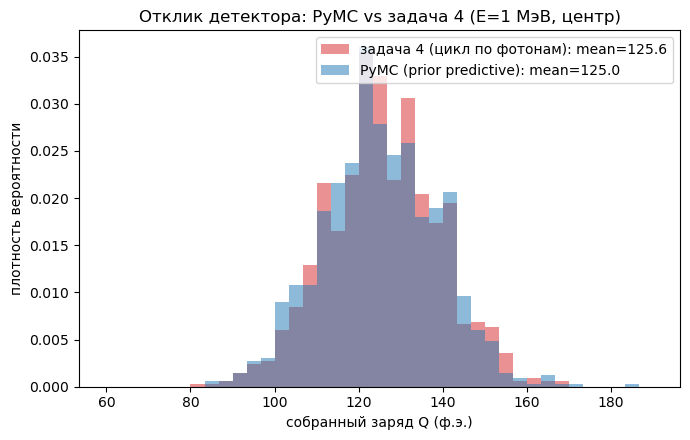

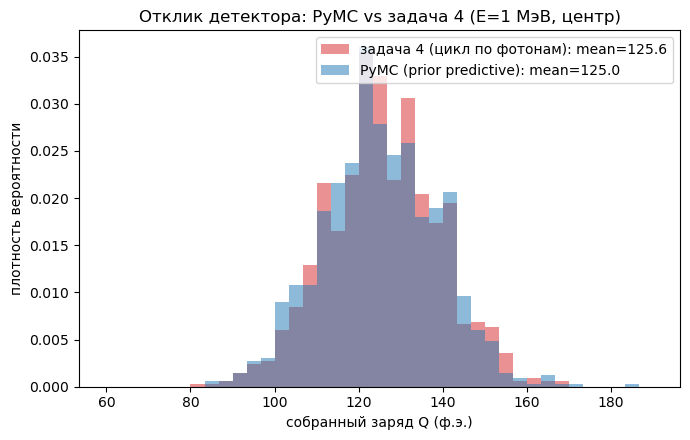

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.linspace(60, 190, 40)
ax.hist(charges_task4, bins=bins, alpha=0.5, color='tab:red', density=True,
        label=f'задача 4 (цикл по фотонам): mean={charges_task4.mean():.1f}')
ax.hist(Q_samples, bins=bins, alpha=0.5, color='tab:blue', density=True,
        label=f'PyMC (prior predictive): mean={Q_samples.mean():.1f}')
ax.set_xlabel('собранный заряд Q (ф.э.)')
ax.set_ylabel('плотность вероятности')
ax.set_title('Отклик детектора: PyMC vs задача 4 (E=1 МэВ, центр)')
ax.legend()
fig.tight_layout()
fig